# Lab: Online Machine Learning with River and CapyMOA





---
## Part 1: River

### Step 1. Installation

**Objective:** Install River in a Python 3.11+ environment, verify the environment, and define the shared configuration from `src/config.py` and plotting helpers from `src/plotting.py`.

In [3]:
!pip install river

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 7.0 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: narwhals
    Found existing installation: narwhals 2.24.0
    Uninstalling narwhals-2.24.0:
      Successfully uninstalled narwhals-2.24.0

[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [4]:
import importlib
import os
import platform
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import river
from IPython.display import Image, display

# Make `src` importable both directly and via `Online_Machine_learning_Lab.src`
ROOT = Path.cwd()
for p in (str(ROOT), str(ROOT / "src")):
    if p not in sys.path:
        sys.path.insert(0, p)

import src

pkg = types.ModuleType("Online_Machine_learning_Lab")
pkg.__path__ = [str(ROOT)]
pkg.src = src
sys.modules["Online_Machine_learning_Lab"] = pkg
sys.modules["Online_Machine_learning_Lab.src"] = src

from src.config import (
    CLASSIFICATION_DATASETS,
    DRIFT_POSITIONS,
    FIGURES,
    N_MAX,
    REGRESSION_DATASETS,
    ROLLING_WINDOW,
    SEED,
    SYNTHETIC_DATASETS,
    TABLES,
)
from src.plotting import plot_drifts, plot_rolling_losses, rolling

print(f"Python version : {platform.python_version()}")
print(f"River version  : {river.__version__}")

Python version : 3.12.8
River version  : 0.27.0


---
### Step 2. Regression Methods and Datasets

**Objective:** Select 4 online regression methods of different types (tree-based, ensemble-based, linear with adaptive learning rate, and instance-based) and 4 datasets (3 real and 1 synthetic), reusing the implementations in `src/data.py` and `src/models.py`.

#### Methods Selected (`src/models.py`)
All regressors use `scaled_regressor(...)`, which chains online feature scaling (`preprocessing.StandardScaler()`) and online target scaling (`preprocessing.TargetStandardScaler`) learned incrementally without look-ahead:
1. **Tree-based (`HoeffdingTree`)** 
2. **Ensemble-based (`ARF`)** 
3. **Linear with adaptive learning rate (`LinearReg(Adam)`)** 
4. **Other (`KNN`)** 
#### Datasets Selected (`src/data.py`)
1. **`Bikes` (Real, $N=20,000$):** Bike count in Toulouse bike-share stations using weather features, hour, weekday, and one-hot station indicator.
2. **`Taxis` (Real, $N=20,000$):** NYC taxi trip duration in seconds from pickup/dropoff coordinates, Euclidean distance, hour, weekday, and passenger count.
3. **`TrumpApproval` (Real, $N=1,001$):** Daily net approval rating from 6 polling indicators.
4. **`FriedmanDrift` (Synthetic, $N=20,000$):** 10-feature non-linear regression stream (`drift_type="gra"`, global recurring abrupt drift) with ground-truth abrupt drifts at instances **7,000** and **14,000**.

In [5]:
from src.models import KNN_WINDOW, regression_models

reg_summary = pd.DataFrame([
    {"Dataset": "Bikes", "Type": "Real", "Samples": N_MAX, "Description": "Toulouse bike-share availability (weather + time + station)"},
    {"Dataset": "Taxis", "Type": "Real", "Samples": N_MAX, "Description": "NYC taxi trip duration in seconds (coords + distance + time)"},
    {"Dataset": "TrumpApproval", "Type": "Real", "Samples": 1001, "Description": "Presidential approval rating (6 polling indicators)"},
    {"Dataset": "FriedmanDrift", "Type": "Synthetic", "Samples": N_MAX, "Description": f"Non-linear stream with abrupt drifts at {DRIFT_POSITIONS}"},
])
print(f"Selected regression models (KNN_WINDOW={KNN_WINDOW}):", list(regression_models().keys()))
display(reg_summary)

Selected regression models (KNN_WINDOW=500): ['HoeffdingTree', 'ARF', 'LinearReg(Adam)', 'KNN']


,Dataset,Type,Samples,Description
0,Bikes,Real,20000,Toulouse bike-share availability (weather + ti...
1,Taxis,Real,20000,NYC taxi trip duration in seconds (coords + di...
2,TrumpApproval,Real,1001,Presidential approval rating (6 polling indica...
3,FriedmanDrift,Synthetic,20000,"Non-linear stream with abrupt drifts at (7000,..."


---
### Step 3. Comparison of Regression Methods


{'dataset': 'Bikes', 'model': 'HoeffdingTree', 'n_samples': 20000, 'MAE': 6.0326, 'RMSE': 8.0729, 'R2': 0.0808, 'time_s': 1.0143, 'latency_ms': 0.0507, 'memory_kb': 264.9238}
{'dataset': 'Bikes', 'model': 'ARF', 'n_samples': 20000, 'MAE': 4.0105, 'RMSE': 5.4771, 'R2': 0.5769, 'time_s': 9.1258, 'latency_ms': 0.4563, 'memory_kb': 411.042}
{'dataset': 'Bikes', 'model': 'LinearReg(Adam)', 'n_samples': 20000, 'MAE': 4.9296, 'RMSE': 6.6358, 'R2': 0.379, 'time_s': 0.3223, 'latency_ms': 0.0161, 'memory_kb': 6.2998}
{'dataset': 'Bikes', 'model': 'KNN', 'n_samples': 20000, 'MAE': 6.2493, 'RMSE': 9.2933, 'R2': -0.2181, 'time_s': 2.6726, 'latency_ms': 0.1336, 'memory_kb': 288.0898}
{'dataset': 'Taxis', 'model': 'HoeffdingTree', 'n_samples': 20000, 'MAE': 533.1575, 'RMSE': 3905.5961, 'R2': -0.0065, 'time_s': 1.3047, 'latency_ms': 0.0652, 'memory_kb': 941.7861}
{'dataset': 'Taxis', 'model': 'ARF', 'n_samples': 20000, 'MAE': 398.8453, 'RMSE': 3876.9836, 'R2': 0.0082, 'time_s': 28.1018, 'latency_ms': 

,dataset,model,n_samples,MAE,RMSE,R2,time_s,latency_ms,memory_kb
0,Bikes,HoeffdingTree,20000,6.0326,8.0729,0.0808,1.0143,0.0507,264.9238
1,Bikes,ARF,20000,4.0105,5.4771,0.5769,9.1258,0.4563,411.0420
2,Bikes,LinearReg(Adam),20000,4.9296,6.6358,0.3790,0.3223,0.0161,6.2998
3,Bikes,KNN,20000,6.2493,9.2933,-0.2181,2.6726,0.1336,288.0898
4,Taxis,HoeffdingTree,20000,533.1575,3905.5961,-0.0065,1.3047,0.0652,941.7861
5,Taxis,ARF,20000,398.8453,3876.9836,0.0082,28.1018,1.4051,50491.6064
6,Taxis,LinearReg(Adam),20000,683.6669,3961.7630,-0.0357,0.3223,0.0161,5.2568
7,Taxis,KNN,20000,583.2417,4219.3448,-0.1747,2.0652,0.1033,310.7031
8,TrumpApproval,HoeffdingTree,1001,0.3913,1.4562,0.2752,0.0445,0.0445,44.0850
9,TrumpApproval,ARF,1001,0.3726,1.4621,0.2694,0.6440,0.6433,1215.7314


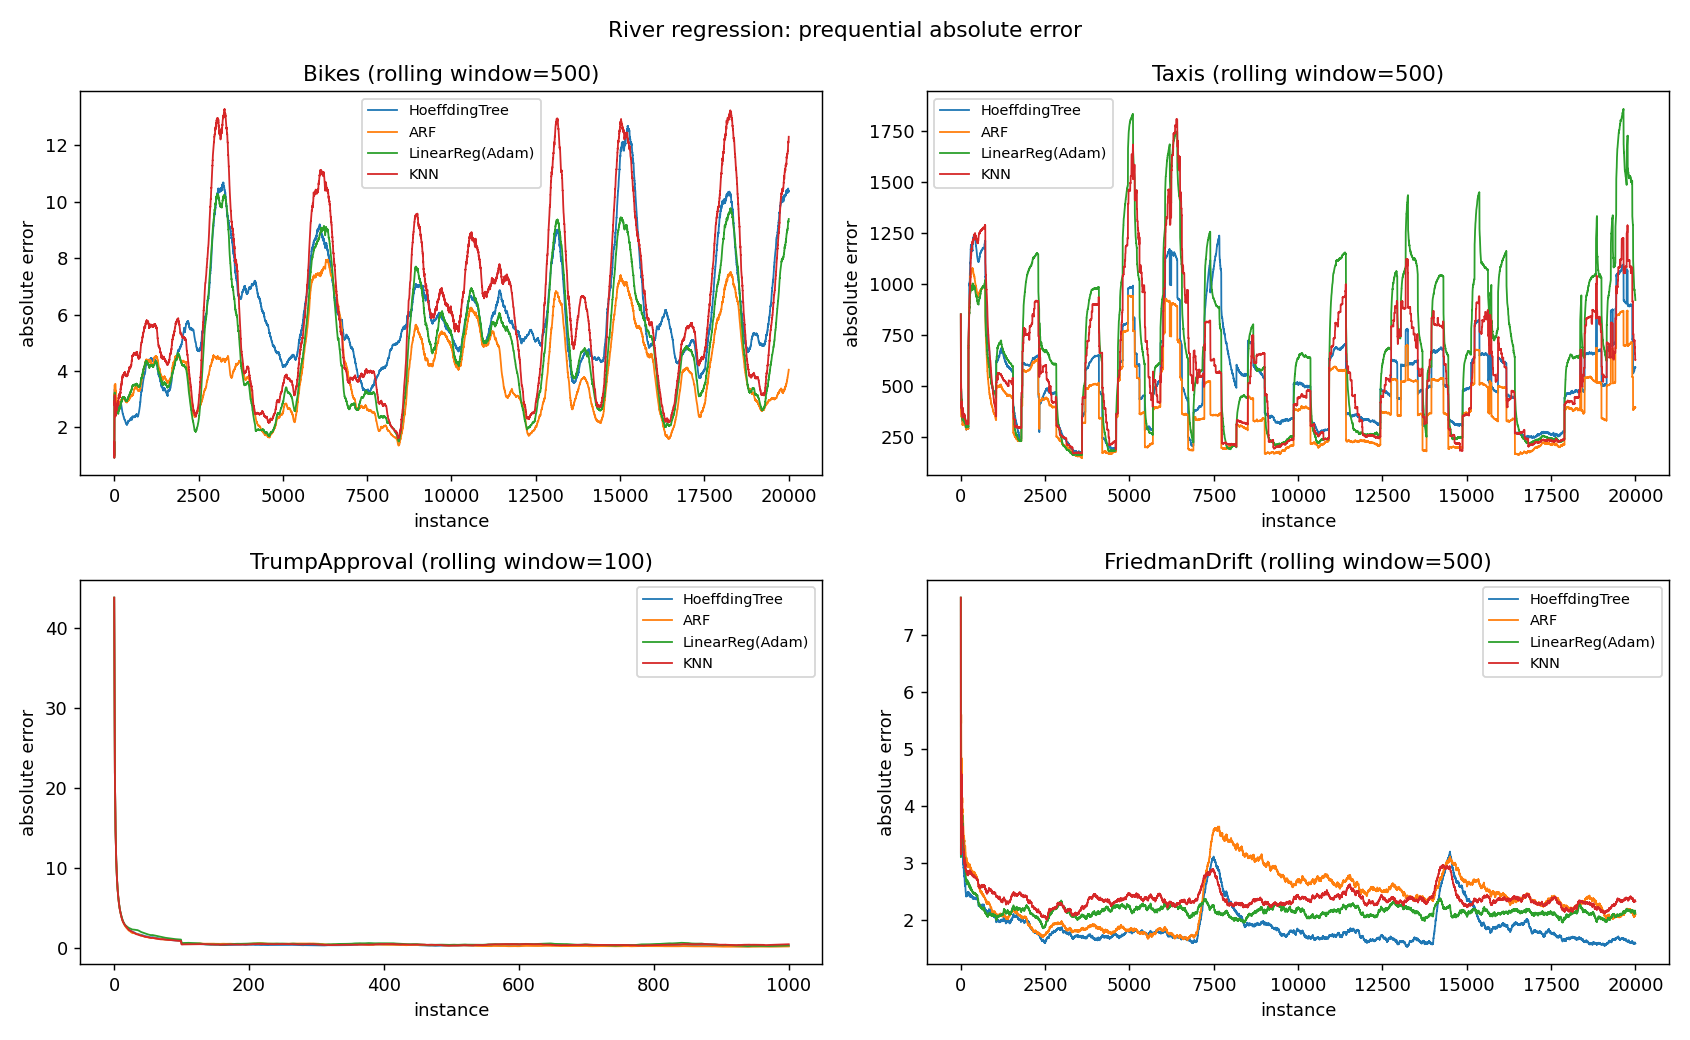

In [6]:
river_comparison = importlib.import_module("01_river_comparison")
compare = river_comparison.compare

river_reg_df = compare("regression")
display(river_reg_df.round(4))
display(Image(filename=str(FIGURES / "river_regression_rolling.png")))

---
### Step 4. Drift Detection (Regression)


Regression drift detectors: ['ADWIN', 'PageHinkley', 'KSWIN']
[regression] Bikes: ADWIN=35, PageHinkley=12, KSWIN=137
[regression] Taxis: ADWIN=4, PageHinkley=10, KSWIN=33
[regression] TrumpApproval: ADWIN=1, PageHinkley=0, KSWIN=5
[regression] FriedmanDrift: ADWIN=7, PageHinkley=2, KSWIN=29
=== Regression Drift Detections ===


,dataset,detector,n_detections,positions,delay@7000,delay@14000,false_alarms
0,Bikes,ADWIN,35,287 799 1119 1727 2399 2623 3327 4383 5471 639...,-,-,-
1,Bikes,PageHinkley,12,847 1721 2596 5618 8627 10473 11054 12745 1457...,-,-,-
2,Bikes,KSWIN,137,141 241 401 525 750 907 1319 1425 1530 1657 17...,-,-,-
3,Taxis,ADWIN,4,2079 3615 10943 12447,-,-,-
4,Taxis,PageHinkley,10,225 1824 3692 4719 5999 7235 13188 15926 18494...,-,-,-
5,Taxis,KSWIN,33,250 377 567 683 1069 1271 1836 2580 2692 3411 ...,-,-,-
6,TrumpApproval,ADWIN,1,479,-,-,-
7,TrumpApproval,PageHinkley,0,,-,-,-
8,TrumpApproval,KSWIN,5,99 279 410 588 868,-,-,-
9,FriedmanDrift,ADWIN,7,1727 7039 7807 12543 14047 14975 18719,39.0,47.0,5.0


=== Regression Drift Handling Performance ===


,dataset,strategy,n_resets,MAE,RMSE,R2,time_s,latency_ms
0,Bikes,No handling,0,6.0326,8.0729,0.0808,0.9944,0.0497
1,Bikes,HAT (built-in),0,2.3301,3.5175,0.8255,1.1838,0.0592
2,Bikes,Reset on ADWIN,54,4.5105,6.2477,0.4495,0.9495,0.0475
3,Bikes,Reset on PageHinkley,10,3.6272,5.8464,0.5179,0.9542,0.0477
4,Bikes,Reset on KSWIN,133,4.8818,6.6928,0.3682,1.8838,0.0942
5,Taxis,No handling,0,533.1575,3905.5961,-0.0065,1.3126,0.0656
6,Taxis,HAT (built-in),0,556.6970,3927.1787,-0.0177,1.7386,0.0869
7,Taxis,Reset on ADWIN,7,597.5350,3949.1767,-0.0291,1.2930,0.0646
8,Taxis,Reset on PageHinkley,9,555.4088,4471.7256,-0.3194,1.0970,0.0549
9,Taxis,Reset on KSWIN,69,563.4418,4105.6657,-0.1123,3.1629,0.1581


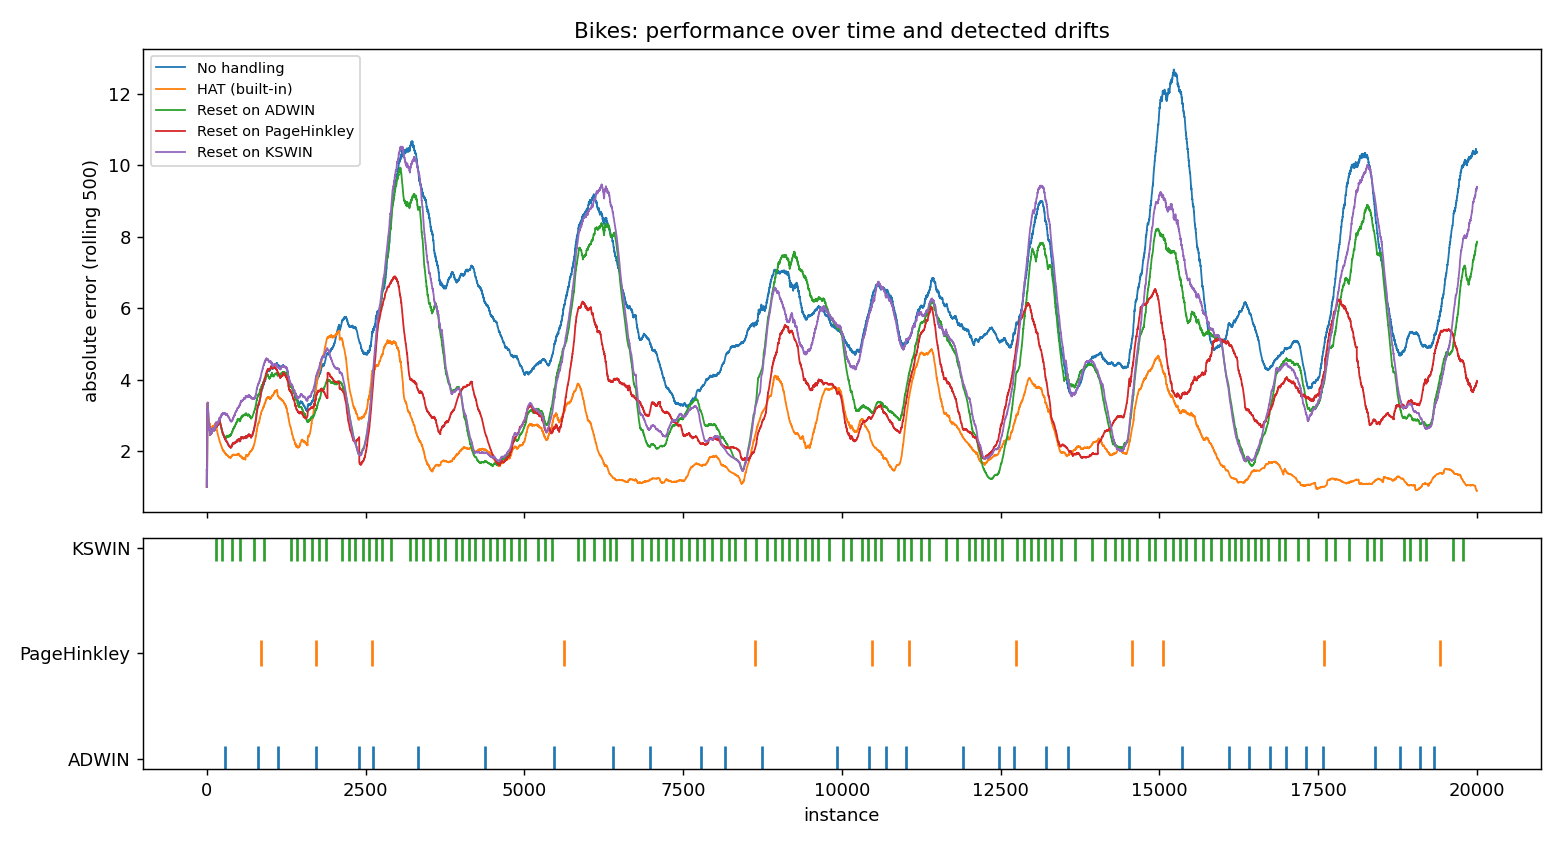

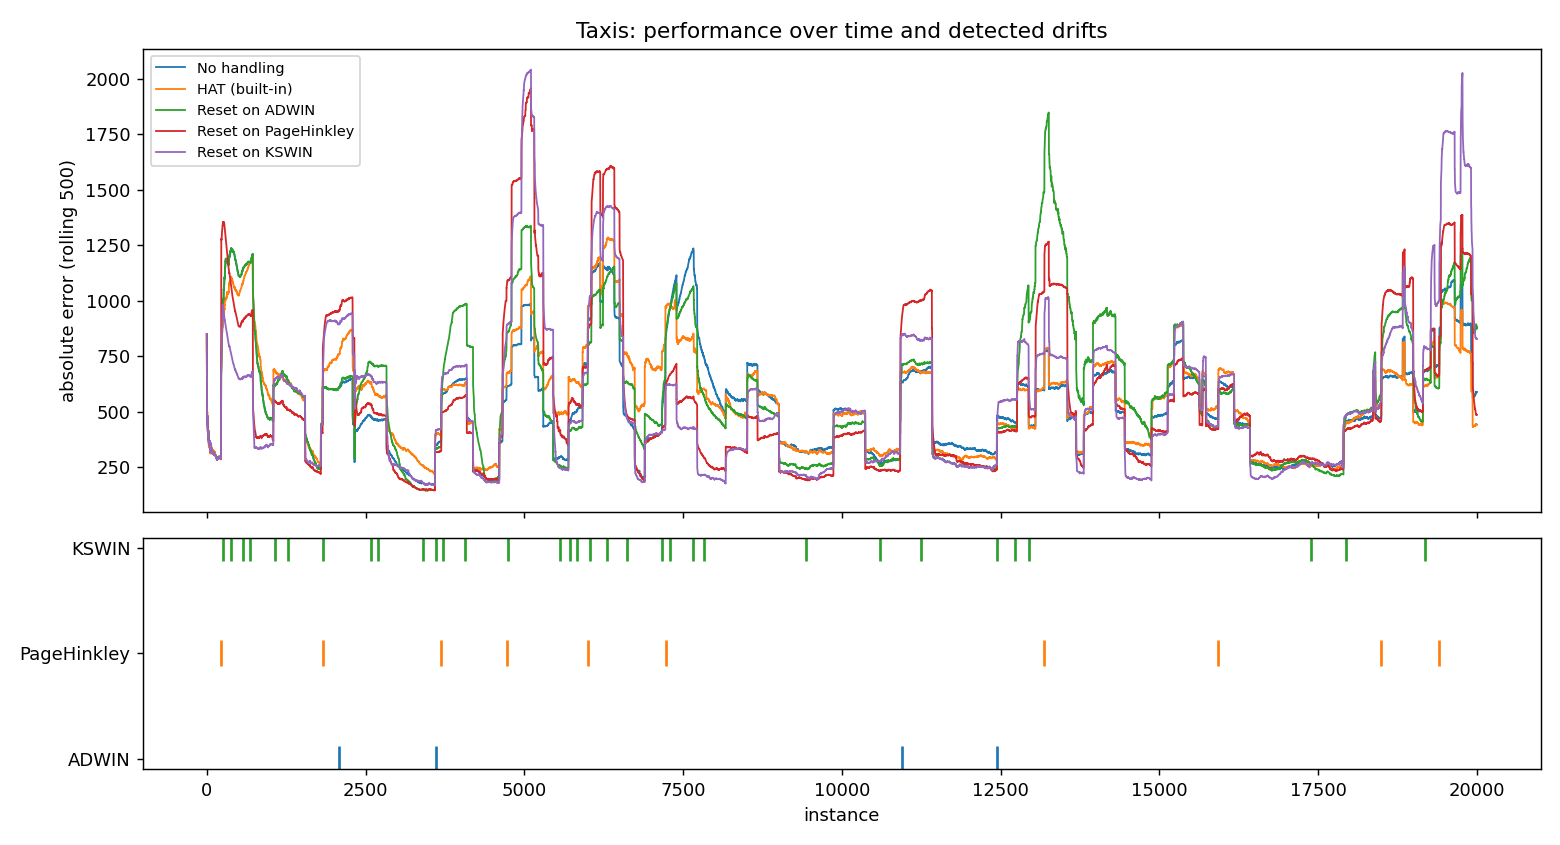

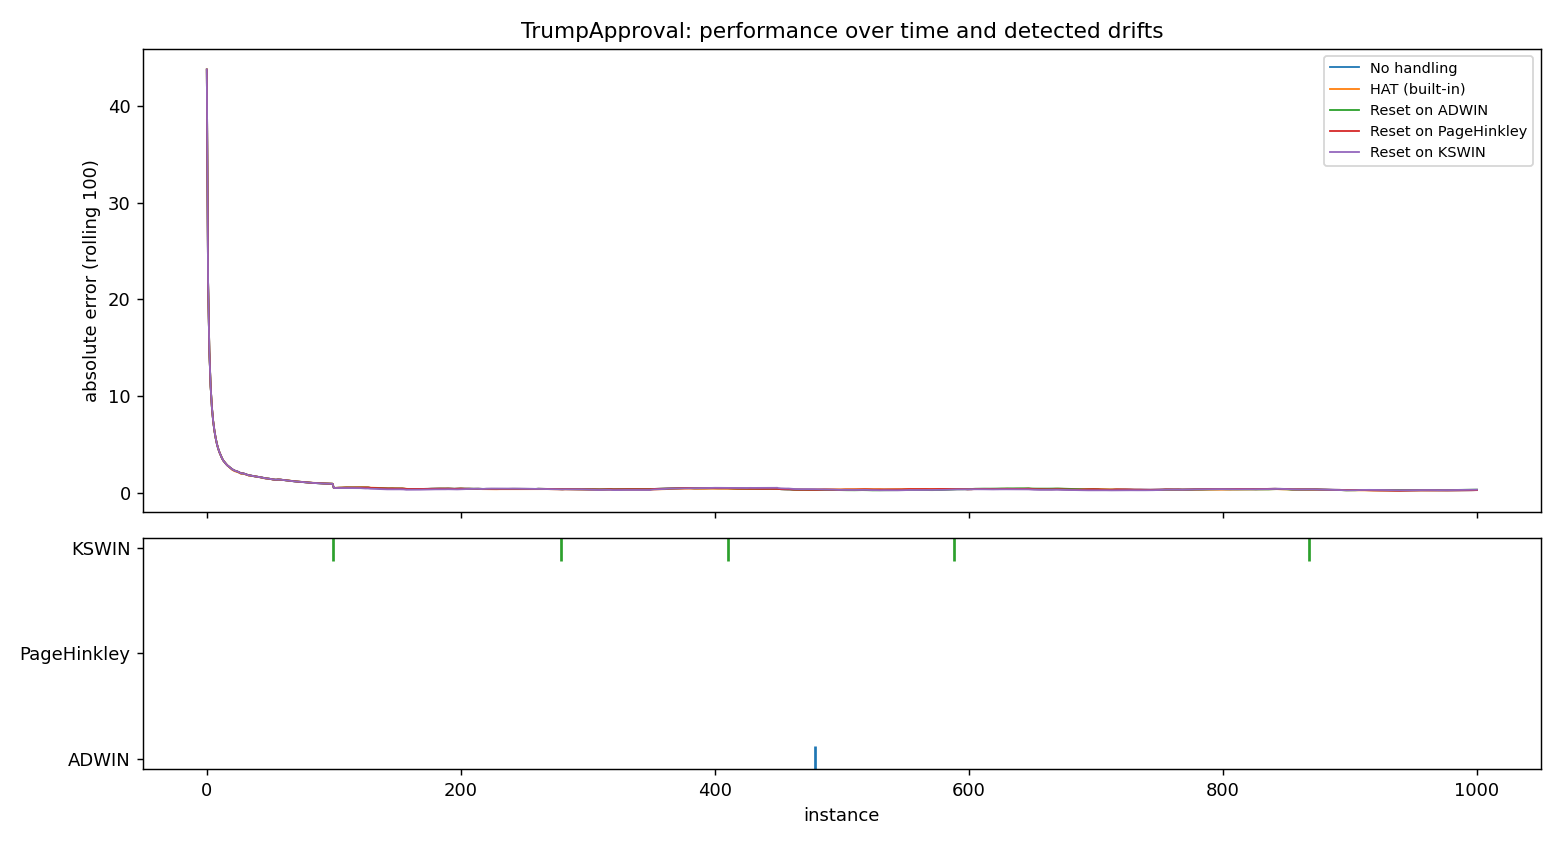

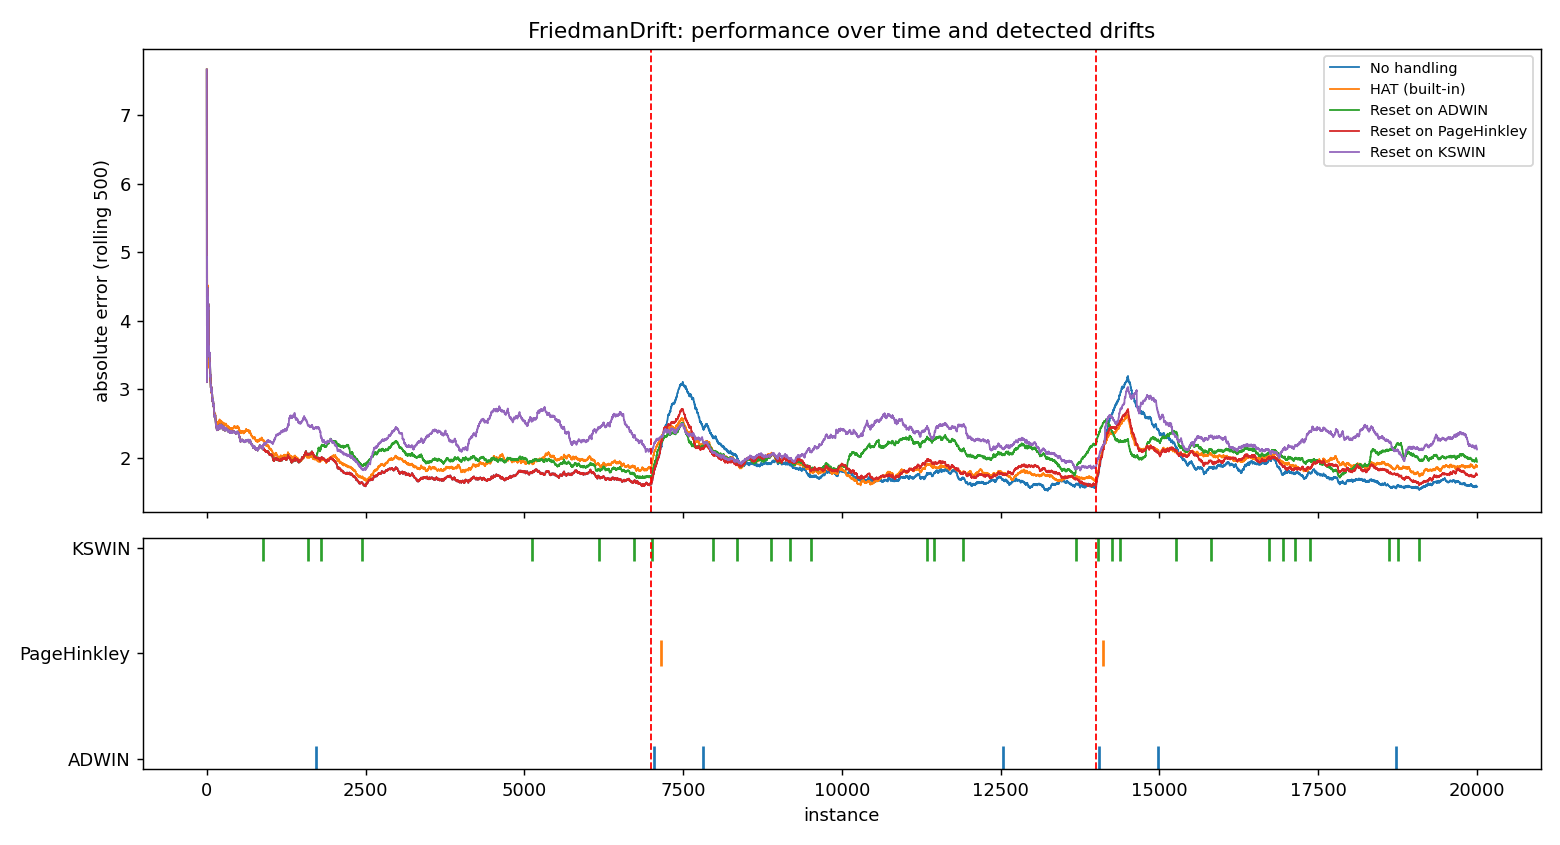

In [7]:
from src.models import regression_detectors

river_drift = importlib.import_module("02_river_drift")
drift_experiment = river_drift.drift_experiment

print("Regression drift detectors:", list(regression_detectors().keys()))
det_reg_df, perf_reg_df = drift_experiment("regression")

print("=== Regression Drift Detections ===")
display(det_reg_df.fillna("-"))
print("=== Regression Drift Handling Performance ===")
display(perf_reg_df.round(4))

for ds in REGRESSION_DATASETS:
    display(Image(filename=str(FIGURES / f"drift_regression_{ds}.png")))

---
### Step 5. Classification: Methods, Datasets, Comparison, and Drift Detection

**Objective:** Repeat Steps 2 to 4 for online classification using 4 classification methods, 3 real datasets and 1 synthetic stream, evaluated with **Accuracy**, **Macro-F1**, and **Cohen's Kappa**, followed by drift detection with 4 binary detectors (`src/data.py`, `src/models.py`, `src/01_river_comparison.py`, and `src/02_river_drift.py`).

#### Classification Setup
* **4 Classification Methods (`src/models.py`):**
  1. **Tree-based (`HoeffdingTree`)** 
  2. **Ensemble-based (`ARF`)** 
  3. **Linear with adaptive learning rate (`LogReg(Adam)`)**
  4. **Other (`GaussianNB`)**
* **4 Classification Datasets (`src/data.py`):**
  1. **`Elec2` (Real, binary, $N=20,000$):** Electricity price movement (up/down) with strong temporal/seasonal drift.
  2. **`Insects` (Real, 6 classes, $N=20,000$):** Optical sensor stream (`abrupt_balanced`, 33 numeric features) with abrupt concept drifts.
  3. **`Phishing` (Real, binary, $N=1,250$):** Website features for phishing detection.
  4. **`SEA_drift` (Synthetic, binary, $N=20,000$):** Nested `ConceptDriftStream` transitioning `SEA(variant=0) -> SEA(variant=1) -> SEA(variant=2)` (`width=50`) at instances **7,000** and **14,000**.
* **4 Classification Drift Detectors (`src/models.py`):** `ADWIN`, `DDM`, `EDDM`, and `HDDM_A`.

Selected classification models (SEA_DRIFT_WIDTH=50): ['HoeffdingTree', 'ARF', 'LogReg(Adam)', 'GaussianNB']
{'dataset': 'Elec2', 'model': 'HoeffdingTree', 'n_samples': 20000, 'Accuracy': 0.8311, 'MacroF1': 0.8261, 'Kappa': 0.6529, 'time_s': 0.0486, 'latency_ms': 0.0024, 'memory_kb': 10.542}
{'dataset': 'Elec2', 'model': 'ARF', 'n_samples': 20000, 'Accuracy': 0.8915, 'MacroF1': 0.8894, 'Kappa': 0.7789, 'time_s': 1.1616, 'latency_ms': 0.0581, 'memory_kb': 144.6924}
{'dataset': 'Elec2', 'model': 'LogReg(Adam)', 'n_samples': 20000, 'Accuracy': 0.8468, 'MacroF1': 0.8433, 'Kappa': 0.6867, 'time_s': 0.4471, 'latency_ms': 0.0224, 'memory_kb': 5.6045}
{'dataset': 'Elec2', 'model': 'GaussianNB', 'n_samples': 20000, 'Accuracy': 0.763, 'MacroF1': 0.7529, 'Kappa': 0.5089, 'time_s': 0.983, 'latency_ms': 0.0491, 'memory_kb': 48.1641}
{'dataset': 'Insects', 'model': 'HoeffdingTree', 'n_samples': 20000, 'Accuracy': 0.5084, 'MacroF1': 0.4874, 'Kappa': 0.41, 'time_s': 0.1159, 'latency_ms': 0.0058, 'memor

,dataset,model,n_samples,Accuracy,MacroF1,Kappa,time_s,latency_ms,memory_kb
0,Elec2,HoeffdingTree,20000,0.8311,0.8261,0.6529,0.0486,0.0024,10.5420
1,Elec2,ARF,20000,0.8915,0.8894,0.7789,1.1616,0.0581,144.6924
2,Elec2,LogReg(Adam),20000,0.8468,0.8433,0.6867,0.4471,0.0224,5.6045
3,Elec2,GaussianNB,20000,0.7630,0.7529,0.5089,0.9830,0.0491,48.1641
4,Insects,HoeffdingTree,20000,0.5084,0.4874,0.4100,0.1159,0.0058,25.4121
5,Insects,ARF,20000,0.7394,0.7336,0.6873,1.9161,0.0958,214.6426
6,Insects,LogReg(Adam),20000,0.7472,0.7451,0.6967,2.8902,0.1445,18.9541
7,Insects,GaussianNB,20000,0.5099,0.4896,0.4118,2.3268,0.1163,585.0020
8,Phishing,HoeffdingTree,1250,0.8799,0.8776,0.7552,0.0033,0.0027,6.3643
9,Phishing,ARF,1250,0.9015,0.9001,0.8002,0.0715,0.0572,168.5576


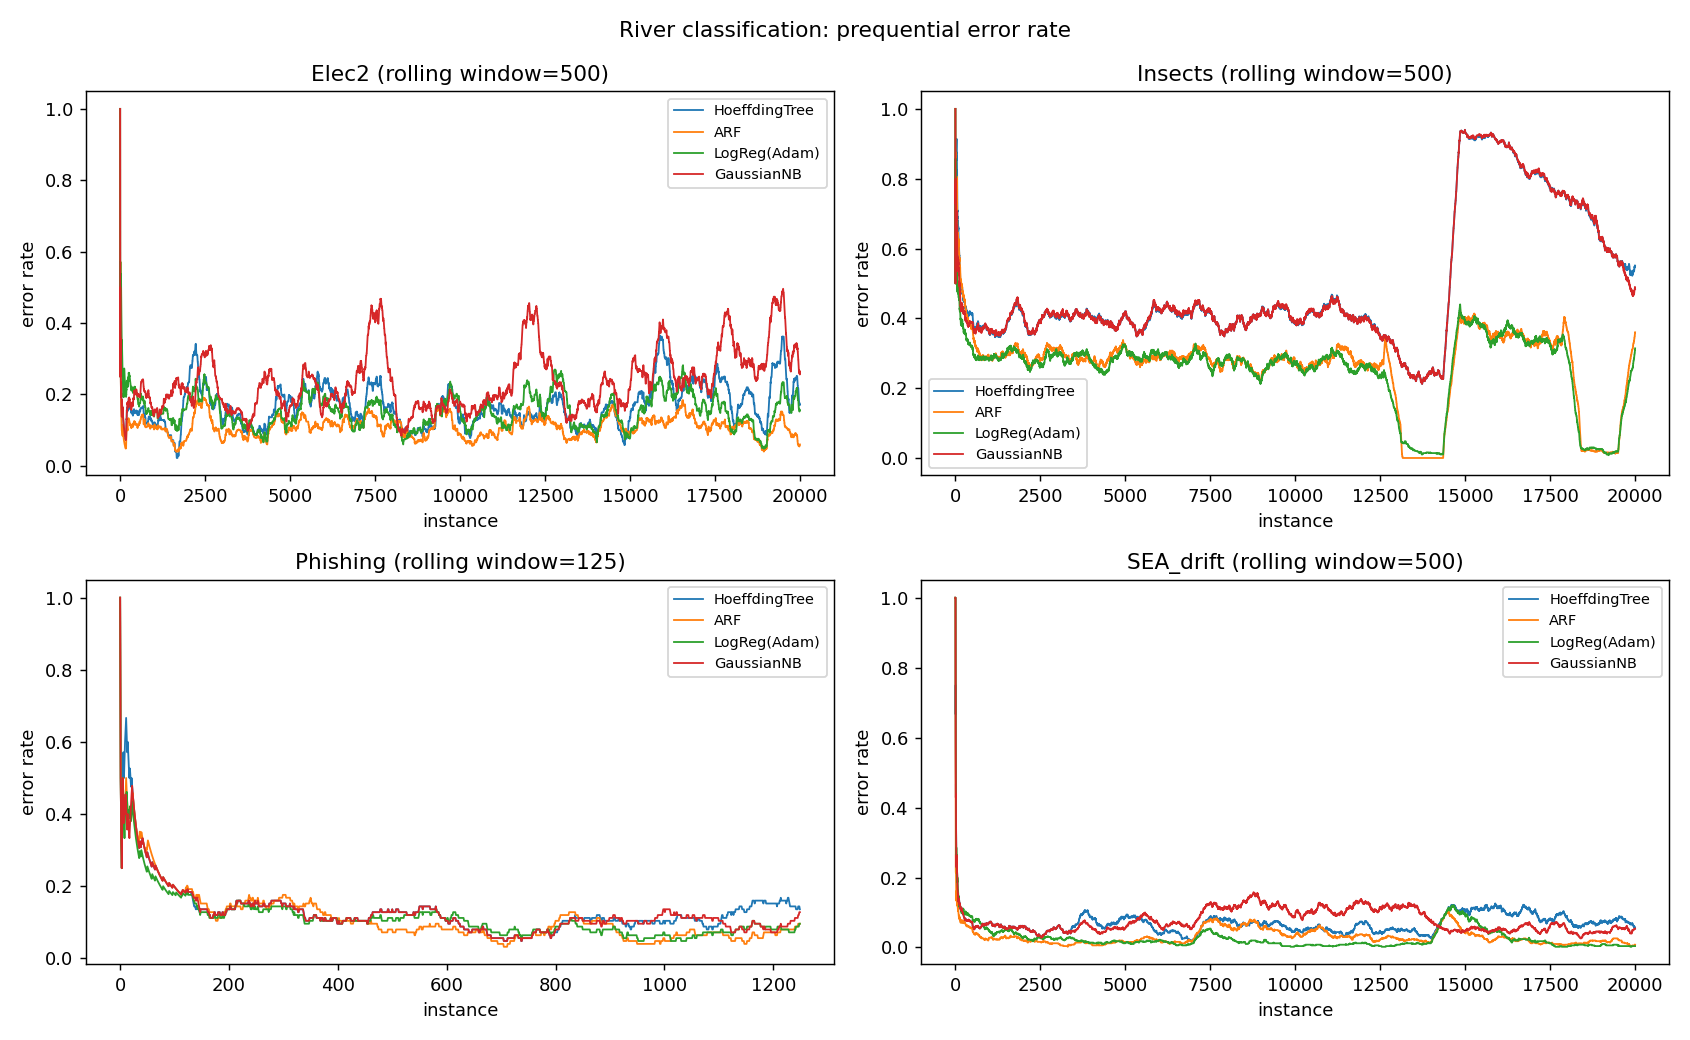

In [8]:
from src.data import SEA_DRIFT_WIDTH, load_classification 
from src.models import classification_models

print(f"Selected classification models (SEA_DRIFT_WIDTH={SEA_DRIFT_WIDTH}):", list(classification_models().keys()))
river_clf_df = compare("classification")
display(river_clf_df.round(4))
display(Image(filename=str(FIGURES / "river_classification_rolling.png")))

Classification drift detectors: ['ADWIN', 'DDM', 'EDDM', 'HDDM_A']
[classification] Elec2: ADWIN=26, DDM=43, EDDM=96, HDDM_A=86
[classification] Insects: ADWIN=4, DDM=1, EDDM=3, HDDM_A=1
[classification] Phishing: ADWIN=0, DDM=0, EDDM=0, HDDM_A=0
[classification] SEA_drift: ADWIN=1, DDM=4, EDDM=8, HDDM_A=1
=== Classification Drift Detections ===


,dataset,detector,n_detections,positions,delay@7000,delay@14000,false_alarms
0,Elec2,ADWIN,26,255 1471 1759 1983 3007 4383 4607 5375 5759 72...,-,-,-
1,Elec2,DDM,43,185 1781 5783 6284 6547 6586 6651 6817 6923 70...,-,-,-
2,Elec2,EDDM,96,197 406 635 894 1115 1725 1789 1843 2040 2136 ...,-,-,-
3,Elec2,HDDM_A,86,184 408 837 1005 1068 1110 1164 1691 1730 1800...,-,-,-
4,Insects,ADWIN,4,12991 14399 16543 18783,-,-,-
5,Insects,DDM,1,14554,-,-,-
6,Insects,EDDM,3,16223 16271 16364,-,-,-
7,Insects,HDDM_A,1,14361,-,-,-
8,Phishing,ADWIN,0,,-,-,-
9,Phishing,DDM,0,,-,-,-


=== Classification Drift Handling Performance ===


,dataset,strategy,n_resets,Accuracy,MacroF1,Kappa,time_s,latency_ms
0,Elec2,No handling,0,0.8311,0.8261,0.6529,0.0492,0.0025
1,Elec2,HAT (built-in),0,0.8612,0.8586,0.7173,1.0992,0.0550
2,Elec2,Reset on ADWIN,20,0.8607,0.8580,0.7160,0.0535,0.0027
3,Elec2,Reset on DDM,68,0.8650,0.8630,0.7260,0.0588,0.0029
4,Elec2,Reset on EDDM,77,0.8575,0.8553,0.7105,0.0544,0.0027
5,Elec2,Reset on HDDM_A,60,0.8679,0.8657,0.7314,0.2342,0.0117
6,Insects,No handling,0,0.5084,0.4874,0.4100,0.1159,0.0058
7,Insects,HAT (built-in),0,0.5532,0.5345,0.4638,3.7505,0.1875
8,Insects,Reset on ADWIN,10,0.6284,0.6088,0.5542,0.1124,0.0056
9,Insects,Reset on DDM,9,0.5976,0.5794,0.5172,0.1231,0.0062


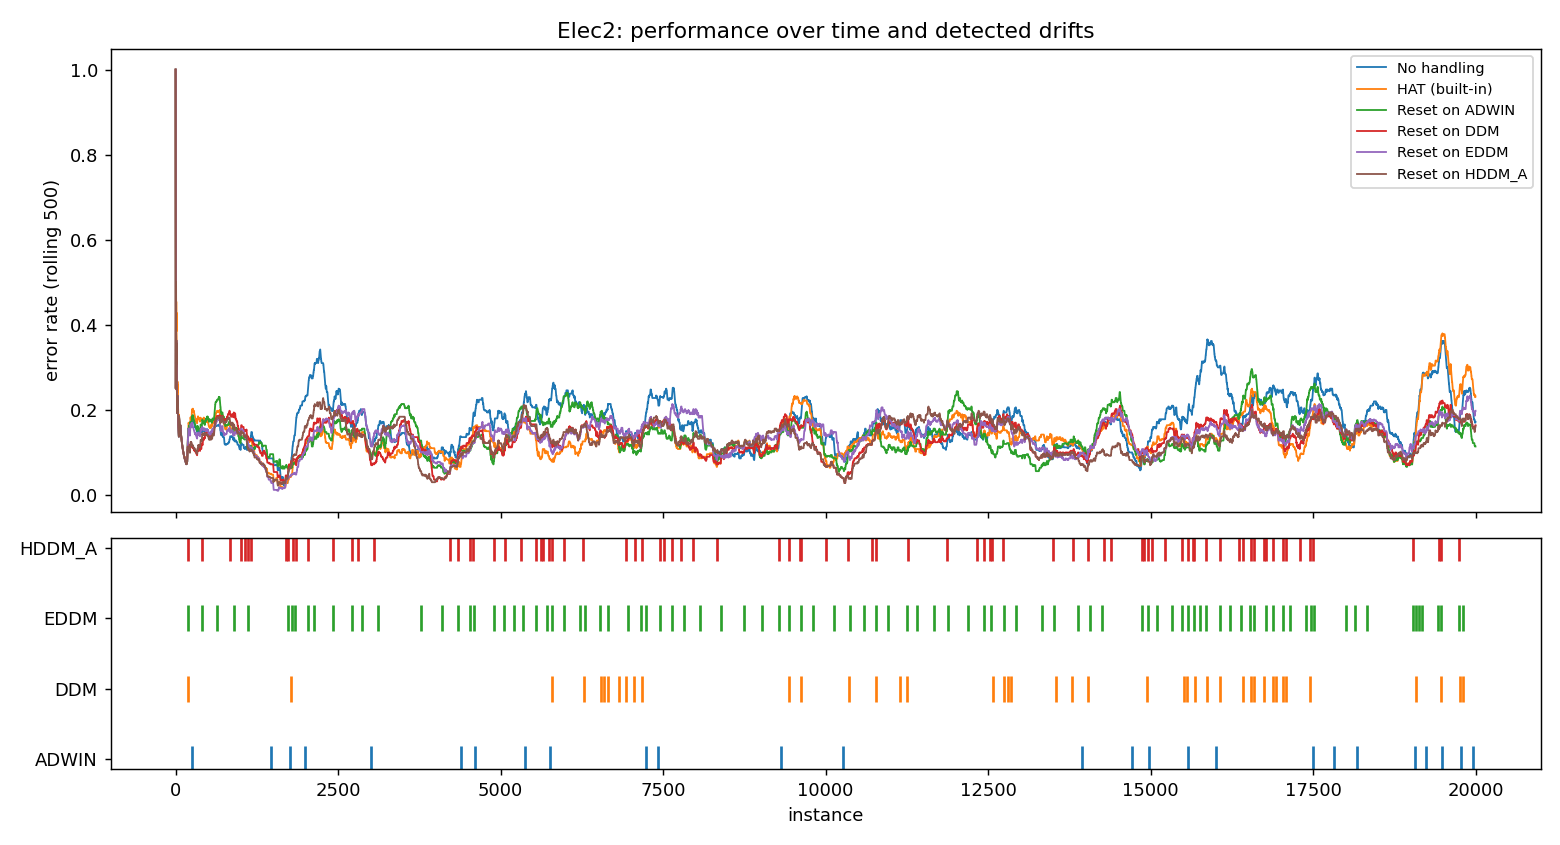

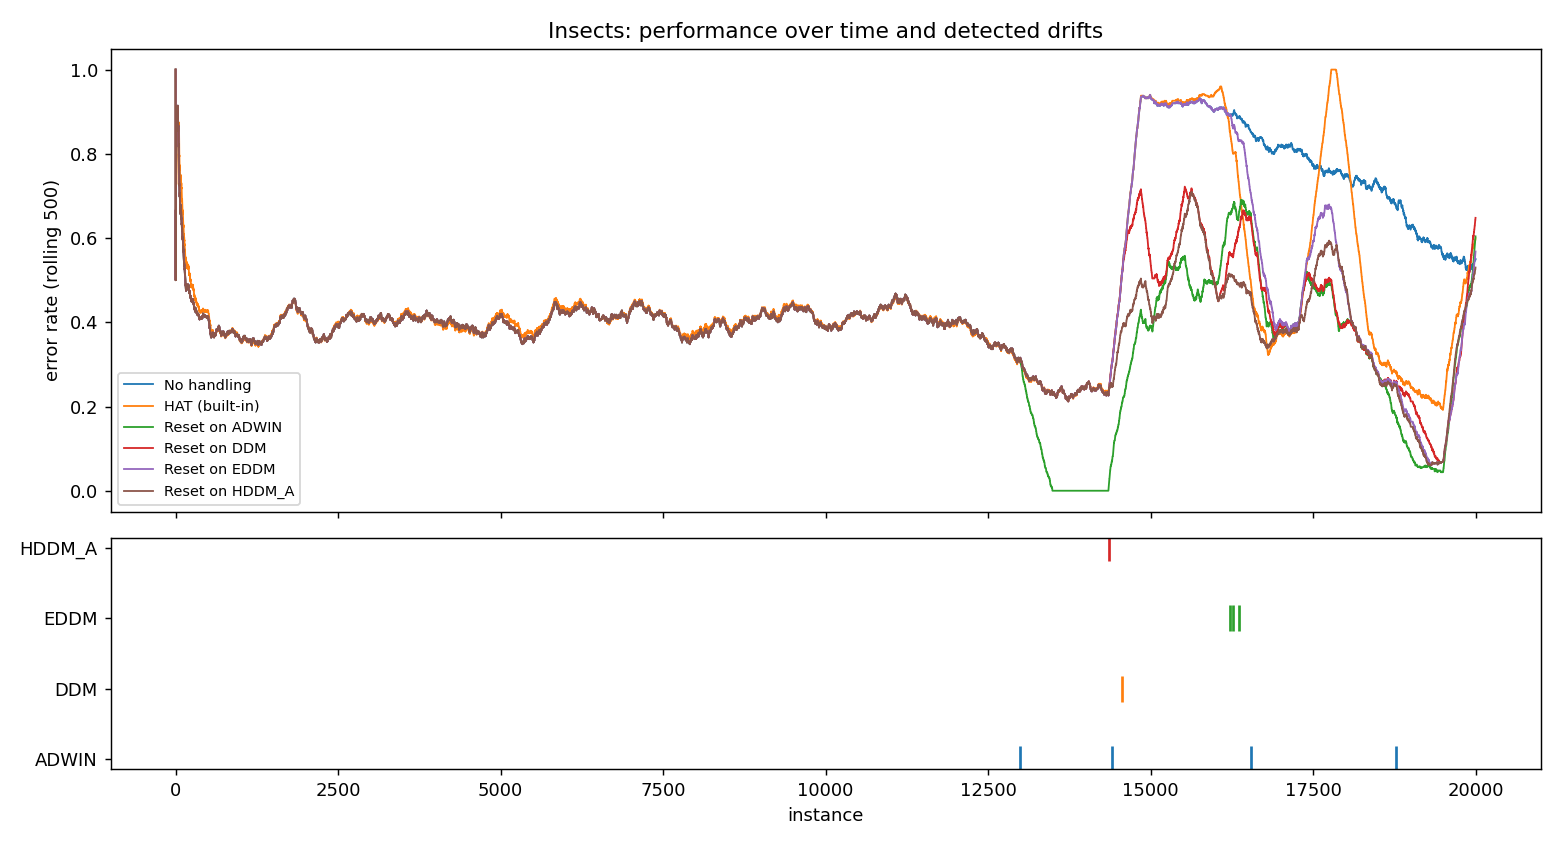

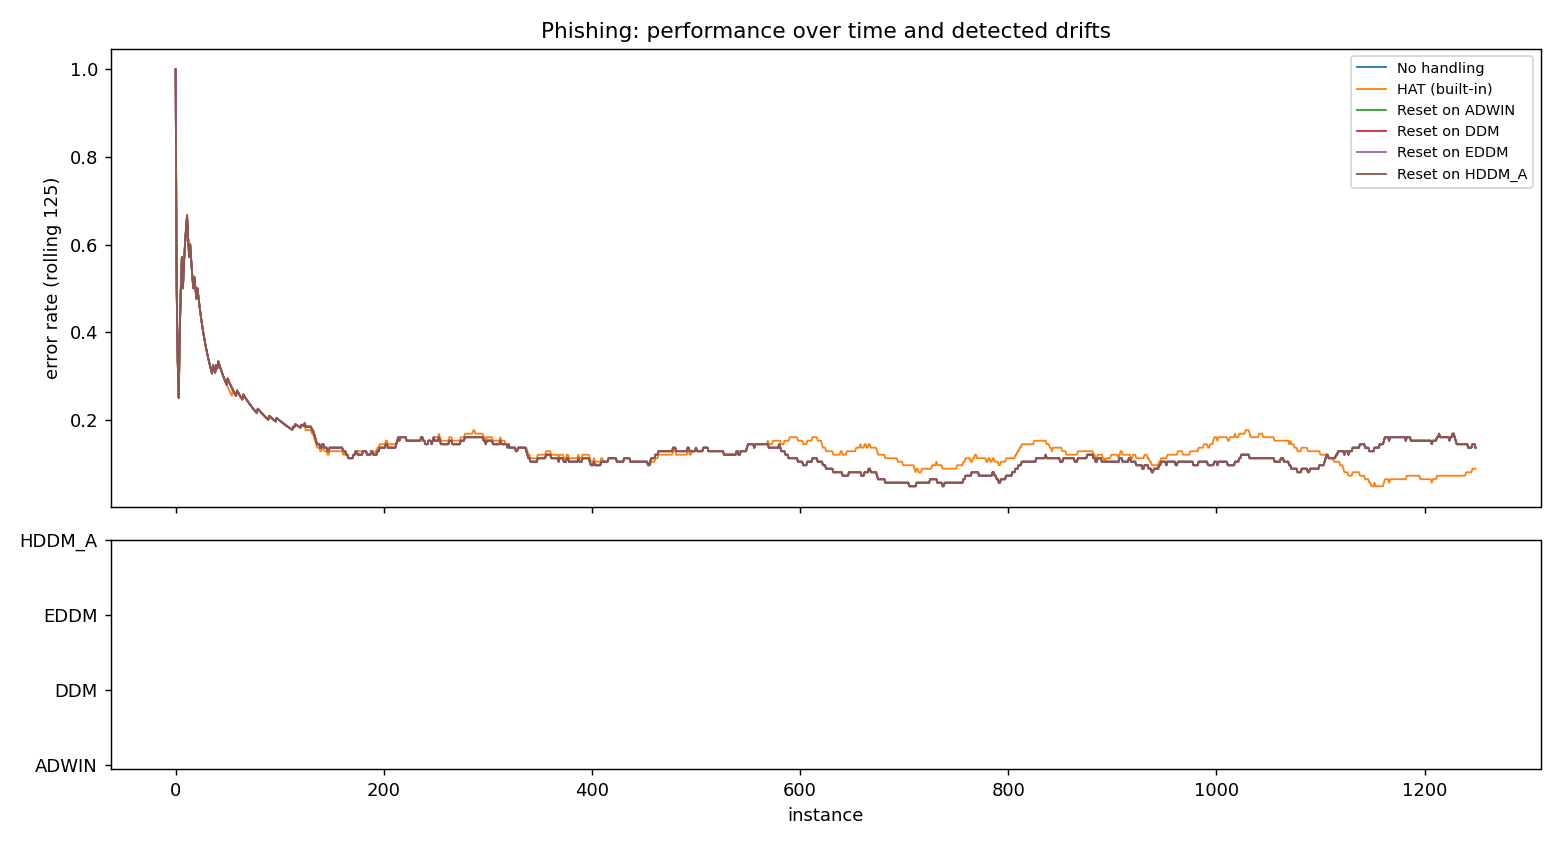

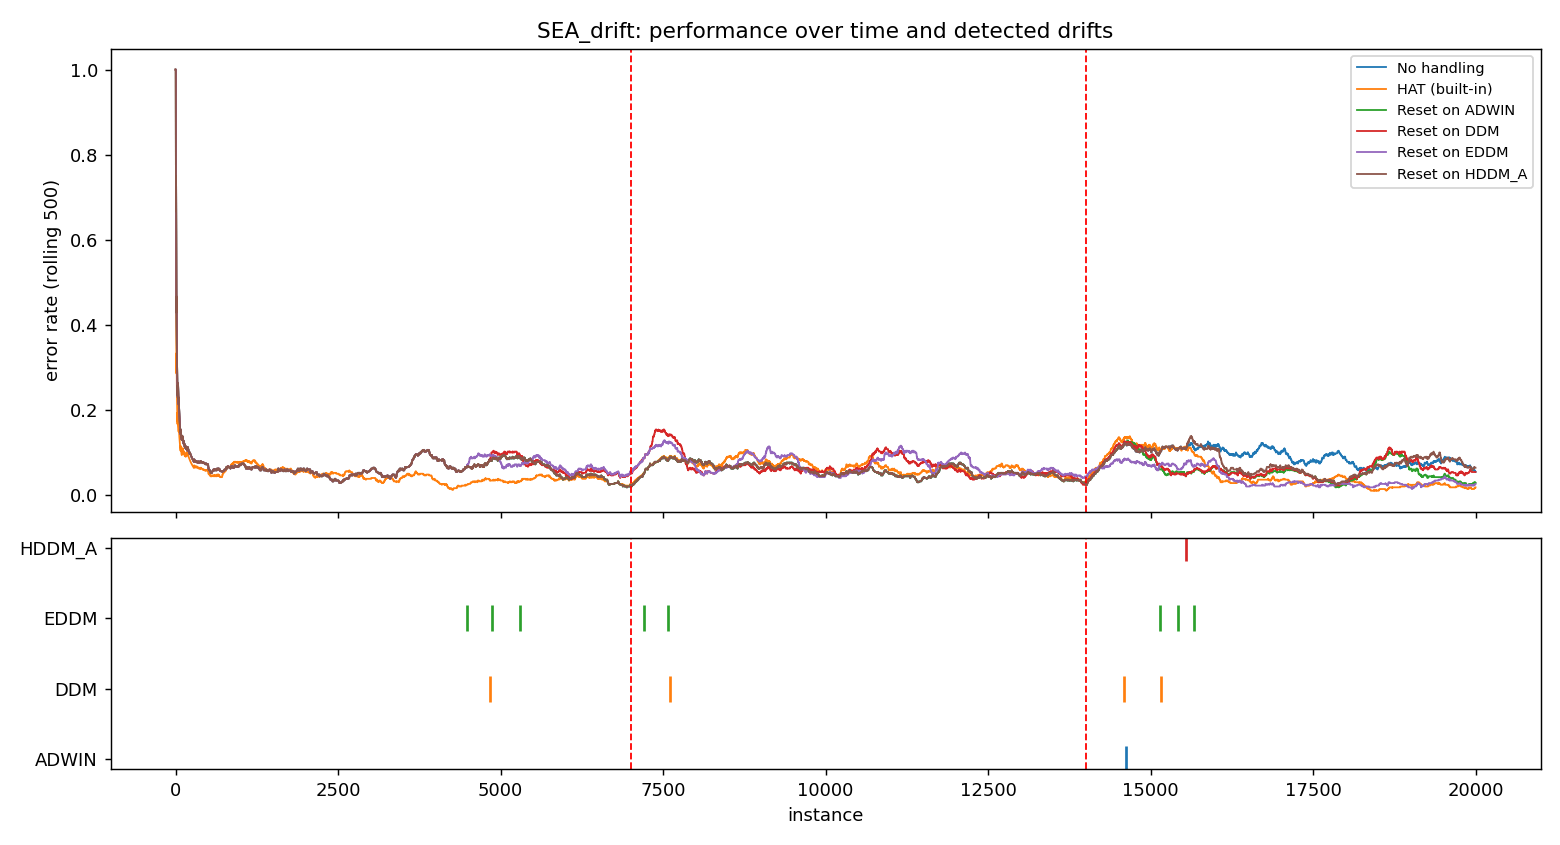

In [9]:
from src.models import classification_detectors
print("Classification drift detectors:", list(classification_detectors().keys()))
det_clf_df, perf_clf_df = drift_experiment("classification")

print("=== Classification Drift Detections ===")
display(det_clf_df.fillna("-"))
print("=== Classification Drift Handling Performance ===")
display(perf_clf_df.round(4))

for ds in CLASSIFICATION_DATASETS:
    display(Image(filename=str(FIGURES / f"drift_classification_{ds}.png")))

---
### Step 6. Report and Analysis of Part 1 (River)

#### 1. Accuracy vs. Computational Cost Trade-offs
| Model Family | River Models | Predictive Performance | Latency (`ms/instance`) | Memory (`KB`) | Main Trade-off |
| :--- | :--- | :--- | :---: | :---: | :--- |
| **Tree-based** | `HoeffdingTreeRegressor`, `HoeffdingTreeClassifier` | Strong on smooth/low-dim streams (`FriedmanDrift` $R^2=0.7573$, `SEA_drift` Acc $=93.23\%$). weak on drifting multi-class streams (`Insects` Acc $=50.84\%$) | Fast ($0.015\text{--}0.21\text{ ms}$) | Moderate ($43\text{--}3,013\text{ KB}$) | Low latency, but static splits become outdated after concept drift without a drift mechanism. |
| **Ensemble-based** | `ARFRegressor(10)`, `ARFClassifier(10)` | Best overall on 6/8 datasets (`Bikes` $R^2=0.5769$, `Elec2` Acc $=89.67\%$, `SEA_drift` Acc $=97.98\%$) | Slowest ($0.32\text{--}1.12\text{ ms}$) | Largest ($358\text{--}65,046\text{ KB}$) | Highest accuracy and built-in drift robustness, at $10\times\text{--}70\times$ higher runtime and memory cost. |
| **Linear + Adaptive LR** | `LinearReg(Adam)`, `LogReg(Adam)` | Best on `Insects` ($74.72\%$), close second on `SEA_drift` ($97.59\%$) and `Bikes` ($R^2=0.3790$) | Fastest ($0.012\text{--}0.12\text{ ms}$) | Minimal ($4.2\text{--}10.2\text{ KB}$) | Ideal for strict latency/memory budgets; Adam adapts weights continuously to drift, limited only by linearity. |
| **Other (KNN / NB)** | `KNNRegressor(k=5, w=500)`, `GaussianNB` | Competitive on short/simple streams (`Phishing` $88.47\%$, `TrumpApproval` $R^2=0.2370$); lags on complex streams | Low–Moderate ($0.04\text{--}0.16\text{ ms}$) | Low–Moderate ($18\text{--}541\text{ KB}$) | `GaussianNB` assumes feature independence and never forgets old statistics; `KNN` struggles with noise and high dimensions. |


In [11]:
!pip install capymoa

jdk_path = "/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home"
if "JAVA_HOME" not in os.environ and os.path.exists(jdk_path):
    os.environ["JAVA_HOME"] = jdk_path

import capymoa
import jpype

print(f"CapyMOA version : {capymoa.__version__}")

  Using cached capymoa-0.15.1-py3-none-any.whl.metadata (6.1 kB)
  Using cached deprecated-1.3.1-py2.py3-none-any.whl.metadata (5.9 kB)
Using cached capymoa-0.15.1-py3-none-any.whl (62.5 MB)
Using cached deprecated-1.3.1-py2.py3-none-any.whl (11 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 569.7/569.7 kB 9.2 MB/s eta 0:00:00

[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
CapyMOA version : 0.15.1


---
### Step 8. Classification Comparison: CapyMOA vs. River

**Objective:** Select the 4 equivalent classification methods in CapyMOA, evaluate them prequentially on the exact same 4 classification streams (`Elec2`, `Insects`, `Phishing`, `SEA_drift`), and compare **Accuracy**, **Macro-F1**, **Kappa**, **runtime**, and **latency** with River (`src/03_capymoa_classification.py`).


{'dataset': 'Elec2', 'model': 'HoeffdingTree', 'n_samples': 20000, 'Accuracy': 0.8419, 'MacroF1': 0.839, 'Kappa': 0.6781, 'time_s': 0.9138, 'cpu_time_s': 1.1973, 'latency_ms': 0.0457}
{'dataset': 'Elec2', 'model': 'ARF', 'n_samples': 20000, 'Accuracy': 0.8855, 'MacroF1': 0.8832, 'Kappa': 0.7665, 'time_s': 3.6839, 'cpu_time_s': 6.8181, 'latency_ms': 0.1842}
{'dataset': 'Elec2', 'model': 'LogReg(SGD)', 'n_samples': 20000, 'Accuracy': 0.8575, 'MacroF1': 0.8537, 'Kappa': 0.7078, 'time_s': 5.7112, 'cpu_time_s': 5.6294, 'latency_ms': 0.2856}
{'dataset': 'Elec2', 'model': 'GaussianNB', 'n_samples': 20000, 'Accuracy': 0.772, 'MacroF1': 0.762, 'Kappa': 0.5271, 'time_s': 0.6901, 'cpu_time_s': 0.7152, 'latency_ms': 0.0345}
{'dataset': 'Insects', 'model': 'HoeffdingTree', 'n_samples': 20000, 'Accuracy': 0.5125, 'MacroF1': 0.4926, 'Kappa': 0.4149, 'time_s': 0.9755, 'cpu_time_s': 1.0919, 'latency_ms': 0.0488}
{'dataset': 'Insects', 'model': 'ARF', 'n_samples': 20000, 'Accuracy': 0.735, 'MacroF1': 0.

,dataset,model,n_samples,Accuracy,MacroF1,Kappa,time_s,cpu_time_s,latency_ms
0,Elec2,HoeffdingTree,20000,0.8419,0.8390,0.6781,0.9138,1.1973,0.0457
1,Elec2,ARF,20000,0.8855,0.8832,0.7665,3.6839,6.8181,0.1842
2,Elec2,LogReg(SGD),20000,0.8575,0.8537,0.7078,5.7112,5.6294,0.2856
3,Elec2,GaussianNB,20000,0.7720,0.7620,0.5271,0.6901,0.7152,0.0345
4,Insects,HoeffdingTree,20000,0.5125,0.4926,0.4149,0.9755,1.0919,0.0488
5,Insects,ARF,20000,0.7350,0.7323,0.6820,3.3218,3.4194,0.1661
6,Insects,LogReg(SGD),20000,0.6707,0.6732,0.6050,21.6446,21.4977,1.0822
7,Insects,GaussianNB,20000,0.5106,0.4903,0.4126,0.8090,0.8163,0.0404
8,Phishing,HoeffdingTree,1250,0.8792,0.8776,0.7552,0.0439,0.0438,0.0352
9,Phishing,ARF,1250,0.9022,0.9009,0.8017,0.1402,0.1420,0.1122


=== River vs. CapyMOA Comparison ===


,dataset,model,Accuracy_river,MacroF1_river,Kappa_river,time_s_river,latency_ms_river,Accuracy_capymoa,MacroF1_capymoa,Kappa_capymoa,time_s_capymoa,latency_ms_capymoa,speedup_capymoa
0,Elec2,HoeffdingTree,0.8311,0.8261,0.6529,0.0486,0.0024,0.8419,0.8390,0.6781,0.9138,0.0457,0.0532
1,Elec2,ARF,0.8915,0.8894,0.7789,1.1616,0.0581,0.8855,0.8832,0.7665,3.6839,0.1842,0.3153
2,Elec2,LogReg,0.8468,0.8433,0.6867,0.4471,0.0224,0.8575,0.8537,0.7078,5.7112,0.2856,0.0783
3,Elec2,GaussianNB,0.7630,0.7529,0.5089,0.9830,0.0491,0.7720,0.7620,0.5271,0.6901,0.0345,1.4245
4,Insects,HoeffdingTree,0.5084,0.4874,0.4100,0.1159,0.0058,0.5125,0.4926,0.4149,0.9755,0.0488,0.1189
5,Insects,ARF,0.7394,0.7336,0.6873,1.9161,0.0958,0.7350,0.7323,0.6820,3.3218,0.1661,0.5768
6,Insects,LogReg,0.7472,0.7451,0.6967,2.8902,0.1445,0.6707,0.6732,0.6050,21.6446,1.0822,0.1335
7,Insects,GaussianNB,0.5099,0.4896,0.4118,2.3268,0.1163,0.5106,0.4903,0.4126,0.8090,0.0404,2.8762
8,Phishing,HoeffdingTree,0.8799,0.8776,0.7552,0.0033,0.0027,0.8792,0.8776,0.7552,0.0439,0.0352,0.0755
9,Phishing,ARF,0.9015,0.9001,0.8002,0.0715,0.0572,0.9022,0.9009,0.8017,0.1402,0.1122,0.5101


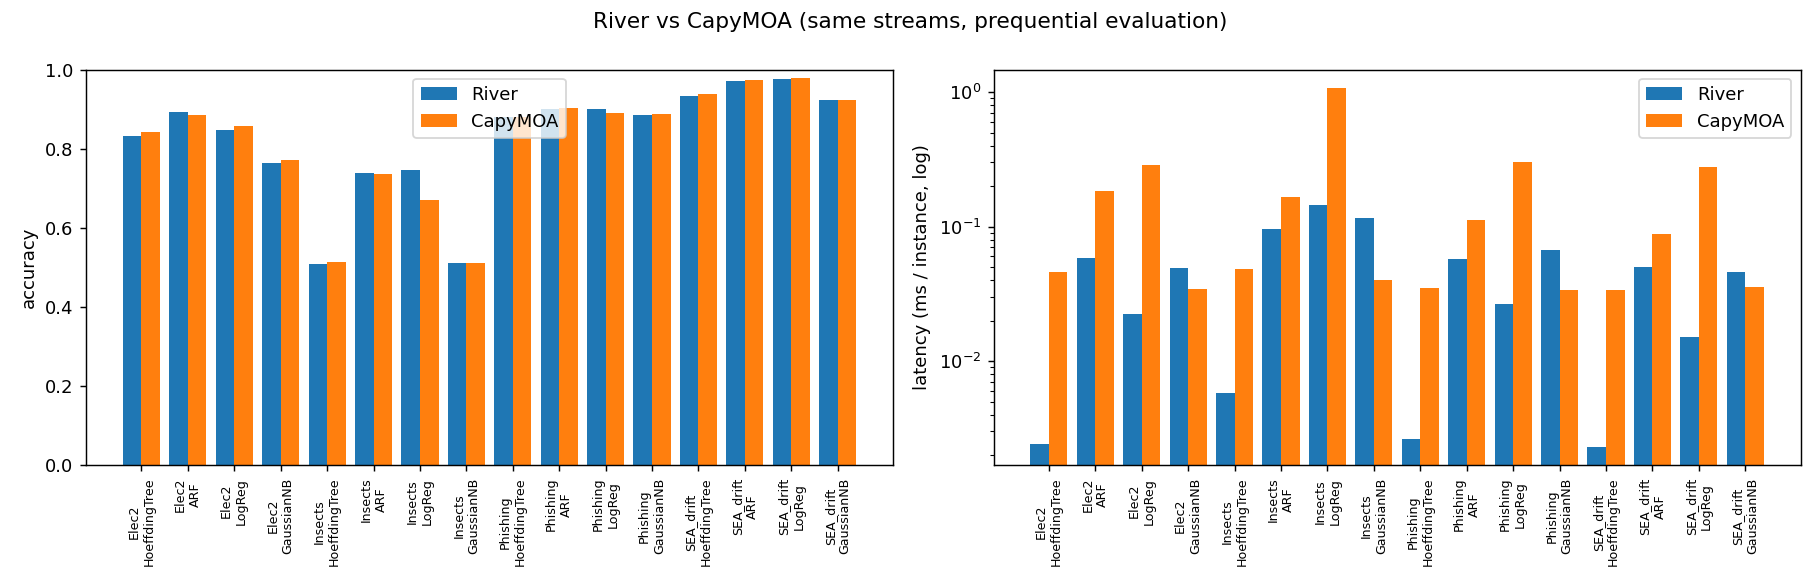

In [12]:
capy_clf = importlib.import_module("03_capymoa_classification")
to_numpy = capy_clf.to_numpy
online_standardize = capy_clf.online_standardize
capymoa_models = capy_clf.capymoa_models
score_predictions = capy_clf.score_predictions
run_capymoa = capy_clf.run_capymoa
compare_with_river = capy_clf.compare_with_river

capy_df = run_capymoa()
merged_df = compare_with_river(capy_df)

print("=== CapyMOA Classification Results ===")
display(capy_df.round(4))
print("=== River vs. CapyMOA Comparison ===")
display(merged_df.round(4))
display(Image(filename=str(FIGURES / "river_vs_capymoa.png")))

---
### Step 9. Stream Clustering in CapyMOA

**Objective:** Evaluate 3 stream clustering algorithms on evolving unsupervised streams, analyzing cluster quality and how the clusters evolve over time (`src/04_capymoa_clustering.py`).

#### Clustering Setup (`src/04_capymoa_clustering.py`)
* **3 Stream Clustering Methods:**
  1. **`CluStream+kMeans`:** `Clustream_with_kmeans(schema, time_window=1000, max_num_kernels=100, k_option=k)` — maintains 100 micro-clusters and groups them into $k$ macro-clusters via $k$-means.
  2. **`DenStream+DBSCAN`:** `Denstream_with_dbscan(schema, horizon=1000, epsilon=0.1, mu=1, init_points=1000)` — density-based micro-clusters with exponential fading and offline DBSCAN macro-clustering (automatically discovers the number of clusters).
  3. **`ClusTree+kMeans`:** `ClusTree(schema, horizon=1000, max_height=8)` — hierarchical tree of micro-clusters with exponential decay, followed by weighted $k$-means on micro-cluster centers.
* **2 Unsupervised Streams (labels used only for evaluation every 1,000 samples):**
  1. **`Blobs_drift` ($N=20,000$, 2D):** 4 Gaussian clusters moving linearly across $[0,1]^2$; **Cluster 4 appears at instance 10,000** (birth) and **Cluster 0 disappears at instance 15,000** (death).
  2. **`Insects` ($N=20,000$, 33D, $k=6$):** Real sensor stream standardized causally via `online_unit_scale(X)`.
* **Metrics:** Evaluated every 1,000 instances using **Silhouette**, **SSQ** (mean squared distance to closest center), **Adjusted Rand Index (ARI)**, **Purity**, **number of clusters (`n_clusters`)**, and **latency (`latency_ms`)**.

{'dataset': 'Blobs_drift', 'method': 'CluStream+kMeans', 'n_samples': 20000, 'mean_n_clusters': 3.95, 'mean_silhouette': 0.626, 'mean_SSQ': 0.0183, 'mean_ARI': 0.7819, 'mean_purity': 0.8419, 'time_s': 2.4757, 'latency_ms': 0.1238}
{'dataset': 'Blobs_drift', 'method': 'DenStream+DBSCAN', 'n_samples': 20000, 'mean_n_clusters': 4.5, 'mean_silhouette': 0.8046, 'mean_SSQ': 0.0049, 'mean_ARI': 0.9984, 'mean_purity': 0.9994, 'time_s': 3.0805, 'latency_ms': 0.154}
{'dataset': 'Blobs_drift', 'method': 'ClusTree+kMeans', 'n_samples': 20000, 'mean_n_clusters': 4.0, 'mean_silhouette': 0.7859, 'mean_SSQ': 0.0048, 'mean_ARI': 0.9435, 'mean_purity': 0.952, 'time_s': 0.8693, 'latency_ms': 0.0435}
{'dataset': 'Insects', 'method': 'CluStream+kMeans', 'n_samples': 20000, 'mean_n_clusters': 6.0, 'mean_silhouette': 0.0956, 'mean_SSQ': 0.0389, 'mean_ARI': 0.2935, 'mean_purity': 0.6217, 'time_s': 21.3071, 'latency_ms': 1.0654}
{'dataset': 'Insects', 'method': 'DenStream+DBSCAN', 'n_samples': 20000, 'mean_n_c

,dataset,method,n_samples,mean_n_clusters,mean_silhouette,mean_SSQ,mean_ARI,mean_purity,time_s,latency_ms
0,Blobs_drift,CluStream+kMeans,20000,3.95,0.6260,0.0183,0.7819,0.8420,2.4757,0.1238
1,Blobs_drift,DenStream+DBSCAN,20000,4.50,0.8046,0.0049,0.9984,0.9994,3.0805,0.1540
2,Blobs_drift,ClusTree+kMeans,20000,4.00,0.7859,0.0048,0.9435,0.9520,0.8693,0.0435
3,Insects,CluStream+kMeans,20000,6.00,0.0956,0.0389,0.2935,0.6217,21.3071,1.0654
4,Insects,DenStream+DBSCAN,20000,9.45,0.0937,0.0357,0.3447,0.6803,31.2113,1.5606
5,Insects,ClusTree+kMeans,20000,6.00,0.1329,0.0335,0.2254,0.5710,1.3039,0.0652


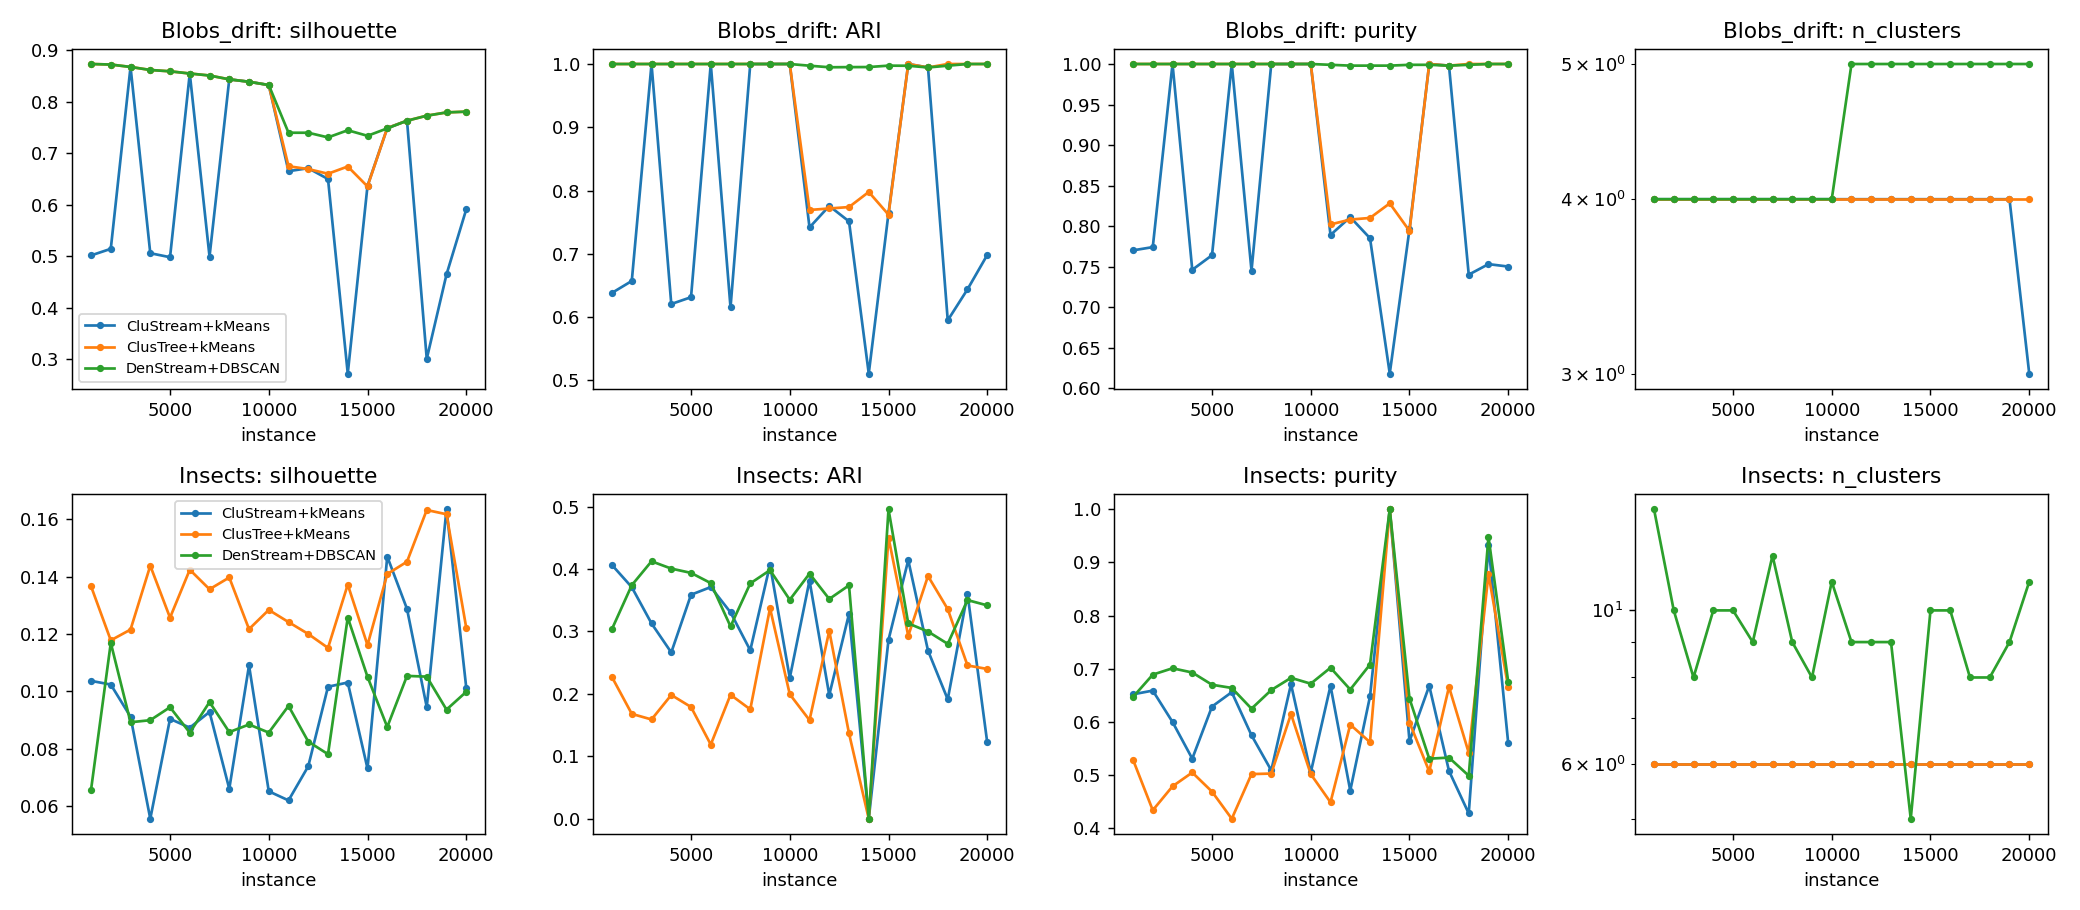

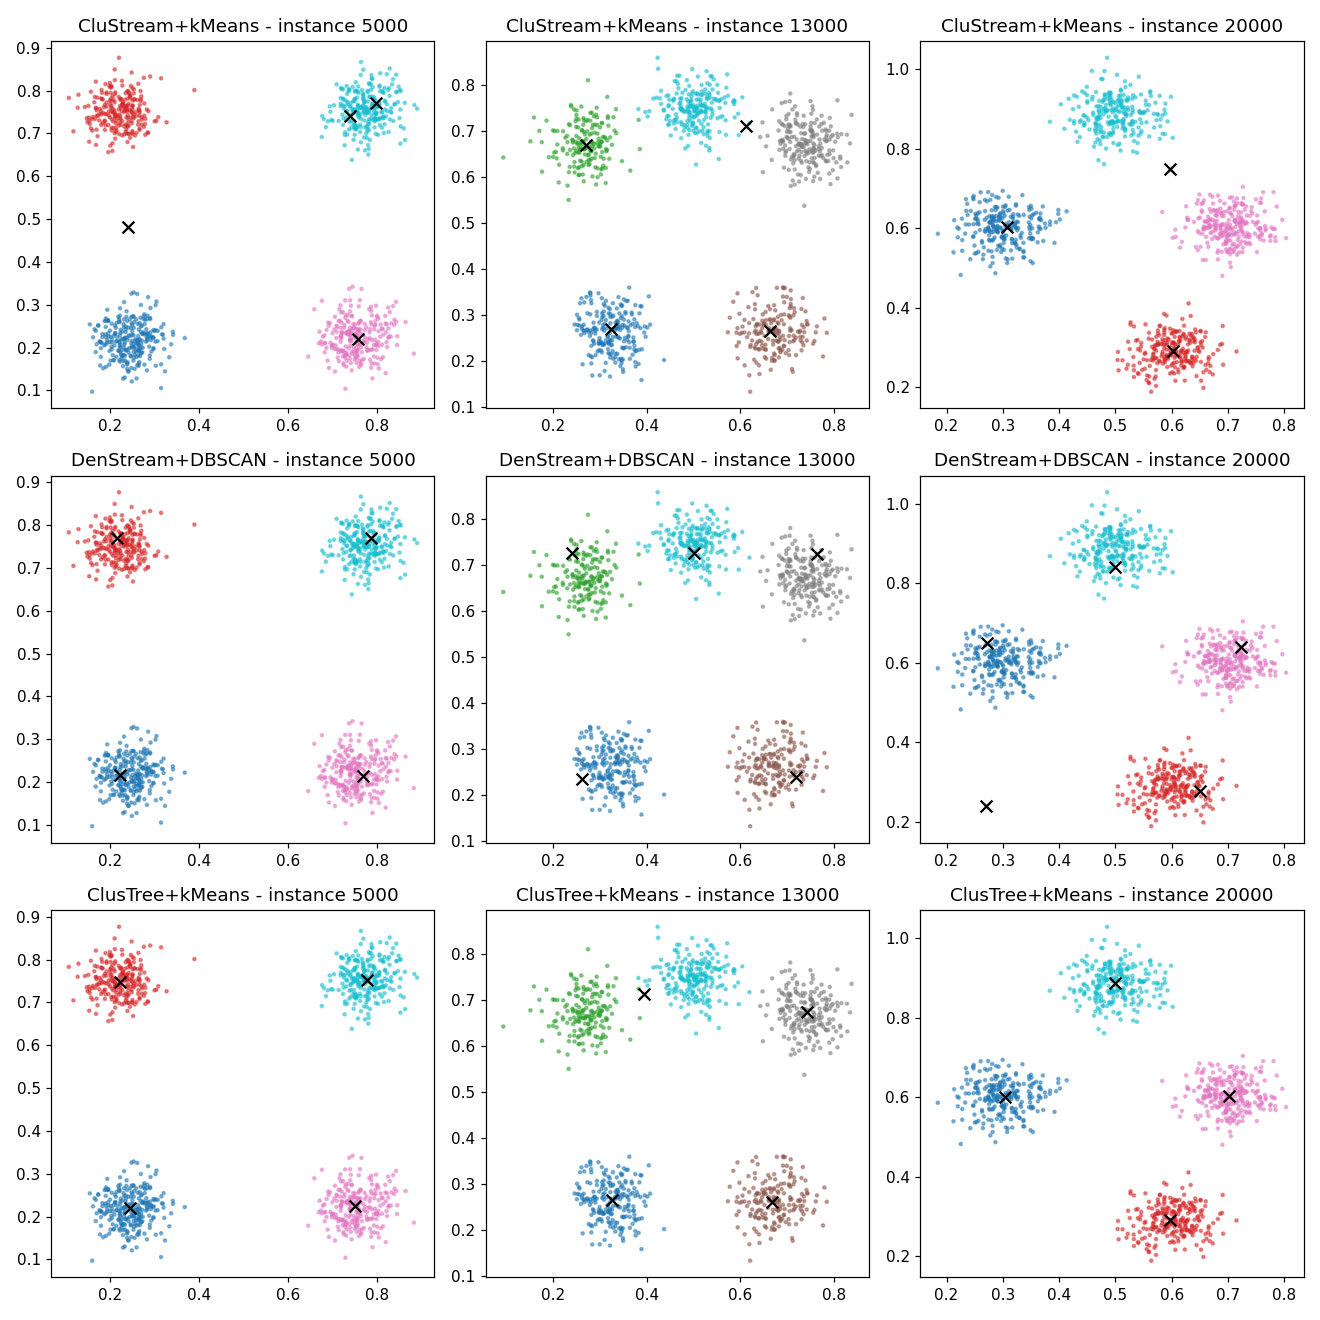

In [13]:
capy_clust = importlib.import_module("04_capymoa_clustering")
DATASETS = capy_clust.DATASETS
EVAL_EVERY = capy_clust.EVAL_EVERY
N_CLUSTERING = capy_clust.N_CLUSTERING
SNAPSHOTS = capy_clust.SNAPSHOTS
blobs_drift_stream = capy_clust.blobs_drift_stream
insects_stream = capy_clust.insects_stream
online_unit_scale = capy_clust.online_unit_scale
clusterers = capy_clust.clusterers
current_centers = capy_clust.current_centers
purity = capy_clust.purity
evaluate_window = capy_clust.evaluate_window
run_clusterer = capy_clust.run_clusterer
plot_over_time = capy_clust.plot_over_time
plot_snapshots = capy_clust.plot_snapshots

summary_rows, time_rows = [], []
for ds, make_stream in DATASETS.items():
    stream, k = make_stream()
    snapshots_by_method = {}
    for method, clusterer in clusterers(stream.get_schema(), k).items():
        records, snapshots, elapsed, n_seen = run_clusterer(stream, clusterer, N_CLUSTERING, k)
        snapshots_by_method[method] = snapshots
        for rec in records:
            time_rows.append({"dataset": ds, "method": method, **rec})
        df_rec = pd.DataFrame(records)
        summary_rows.append({
            "dataset": ds,
            "method": method,
            "n_samples": n_seen,
            **df_rec.drop(columns="instance").mean().add_prefix("mean_").to_dict(),
            "time_s": elapsed,
            "latency_ms": 1000 * elapsed / n_seen,
        })
        print({k_: round(v, 4) if isinstance(v, float) else v for k_, v in summary_rows[-1].items()})
    if ds == "Blobs_drift":
        plot_snapshots(snapshots_by_method)

clust_summary_df = pd.DataFrame(summary_rows)
clust_over_time_df = pd.DataFrame(time_rows)
clust_summary_df.to_csv(TABLES / "capymoa_clustering_summary.csv", index=False)
clust_over_time_df.to_csv(TABLES / "capymoa_clustering_over_time.csv", index=False)
plot_over_time(clust_over_time_df)

print("=== Stream Clustering Summary ===")
display(clust_summary_df.round(4))
display(Image(filename=str(FIGURES / "clustering_over_time.png")))
display(Image(filename=str(FIGURES / "clustering_snapshots_Blobs_drift.png")))

---
### Step 10. Bonus: AutoML in CapyMOA

**Objective:** Explore CapyMOA's `capymoa.automl` module by comparing two online AutoML strategies (`BanditClassifier` with `EpsilonGreedy` and `SuccessiveHalvingClassifier`) against their individual base classifiers on `Elec2` and `SEA_drift` (`src/05_capymoa_automl.py`).

{'dataset': 'Elec2', 'approach': 'single: HT(gp=50)', 'Accuracy': 0.8446870597705776, 'MacroF1': 0.8418437591192551, 'Kappa': 0.6837130598626007, 'time_s': 0.7228820323944092, 'latency_ms': 0.03614410161972046}
{'dataset': 'Elec2', 'approach': 'single: HT(gp=200)', 'Accuracy': 0.8418942620897019, 'MacroF1': 0.8390428301878577, 'Kappa': 0.6781039307498847, 'time_s': 0.7533969879150391, 'latency_ms': 0.03766984939575195}
{'dataset': 'Elec2', 'approach': 'single: HAT', 'Accuracy': 0.8792763656576886, 'MacroF1': 0.8774893767607839, 'Kappa': 0.7549819542477323, 'time_s': 0.8394260406494141, 'latency_ms': 0.0419713020324707}
{'dataset': 'Elec2', 'approach': 'single: NaiveBayes', 'Accuracy': 0.7719921894557653, 'MacroF1': 0.762017661668575, 'Kappa': 0.5271317550575544, 'time_s': 0.7093009948730469, 'latency_ms': 0.035465049743652347}
{'dataset': 'Elec2', 'approach': 'single: ARF(10)', 'Accuracy': 0.9048906242178505, 'MacroF1': 0.9031883441034301, 'Kappa': 0.8063869282889293, 'time_s': 3.50556

,dataset,approach,Accuracy,MacroF1,Kappa,time_s,latency_ms
0,Elec2,single: HT(gp=50),0.8447,0.8418,0.6837,0.7229,0.0361
1,Elec2,single: HT(gp=200),0.8419,0.8390,0.6781,0.7534,0.0377
2,Elec2,single: HAT,0.8793,0.8775,0.7550,0.8394,0.0420
3,Elec2,single: NaiveBayes,0.7720,0.7620,0.5271,0.7093,0.0355
4,Elec2,single: ARF(10),0.9049,0.9032,0.8064,3.5056,0.1753
5,Elec2,AutoML: Bandit (eps-greedy),0.7707,0.7610,0.5249,80.1828,4.0091
6,Elec2,AutoML: Successive Halving,0.9049,0.9032,0.8064,185.2532,9.2627
7,SEA_drift,single: HT(gp=50),0.9372,0.9284,0.8569,0.7149,0.0357
8,SEA_drift,single: HT(gp=200),0.9393,0.9300,0.8600,0.6730,0.0337
9,SEA_drift,single: HAT,0.9626,0.9567,0.9135,0.8029,0.0401


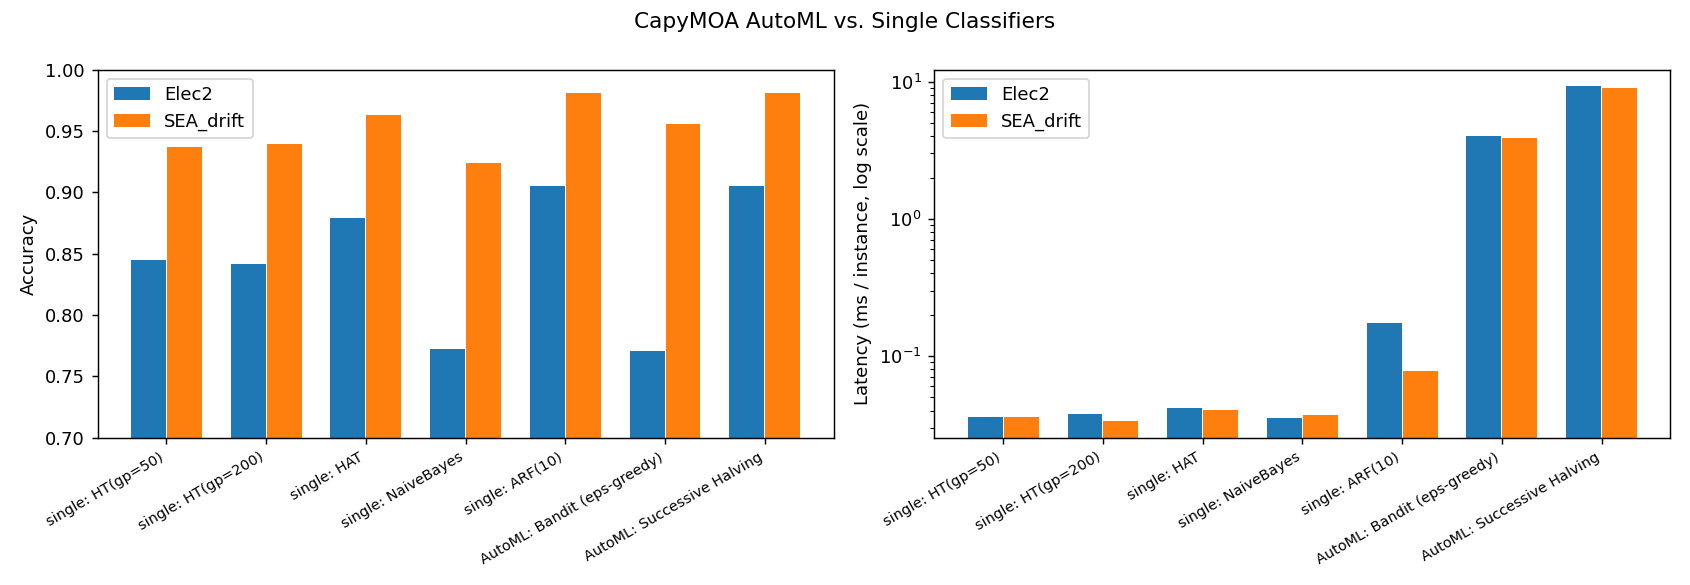

In [14]:
from capymoa.automl import BanditClassifier, EpsilonGreedy, SuccessiveHalvingClassifier
from capymoa.stream import NumpyStream

capy_automl = importlib.import_module("05_capymoa_automl")
AUTOML_DATASETS = capy_automl.AUTOML_DATASETS
candidates = capy_automl.candidates
evaluate = capy_automl.evaluate

automl_rows = []
for ds in AUTOML_DATASETS:
    data = load_classification(ds)
    X, y, names, _ = to_numpy(data)
    stream = NumpyStream(X, y, dataset_name=ds, feature_names=names, target_type="categorical")
    schema, n = stream.get_schema(), len(data)

    for name, model in candidates(schema).items():
        automl_rows.append({"dataset": ds, "approach": f"single: {name}", **evaluate(stream, model, n)})
        print(automl_rows[-1])

    automl_methods = {
        "AutoML: Bandit (eps-greedy)": BanditClassifier(
            schema,
            random_seed=SEED,
            base_classifiers=list(candidates(schema).values()),
            policy=EpsilonGreedy(epsilon=0.1, burn_in=100),
        ),
        "AutoML: Successive Halving": SuccessiveHalvingClassifier(
            schema,
            random_seed=SEED,
            base_classifiers=list(candidates(schema).values()),
            max_instances=n,
        ),
    }
    for name, learner in automl_methods.items():
        automl_rows.append({"dataset": ds, "approach": name, **evaluate(stream, learner, n)})
        print(automl_rows[-1])

automl_df = pd.DataFrame(automl_rows)
automl_df.to_csv(TABLES / "capymoa_automl.csv", index=False)
display(automl_df.round(4))

# Plot Accuracy and Latency comparison across single classifiers and AutoML approaches
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
approaches = automl_df["approach"].unique()
x = np.arange(len(approaches))
for i, ds in enumerate(AUTOML_DATASETS):
    sub = automl_df[automl_df["dataset"] == ds].set_index("approach").loc[approaches]
    offset = -0.18 if i == 0 else 0.18
    axes[0].bar(x + offset, sub["Accuracy"], 0.35, label=ds)
    axes[1].bar(x + offset, sub["latency_ms"], 0.35, label=ds)
for ax in axes:
    ax.set_xticks(x, approaches, rotation=30, ha="right", fontsize=8)
    ax.legend()
axes[0].set_ylim(0.7, 1.0)
axes[0].set_ylabel("Accuracy")
axes[1].set_yscale("log")
axes[1].set_ylabel("Latency (ms / instance, log scale)")
fig.suptitle("CapyMOA AutoML vs. Single Classifiers")
fig.tight_layout()
fig.savefig(FIGURES / "capymoa_automl.png", dpi=130)
plt.close(fig)
display(Image(filename=str(FIGURES / "capymoa_automl.png")))

---
## Overall Conclusion

1. **Choosing an Online Learner (Accuracy vs. Resource Cost):**
   * **Adaptive Random Forest (`ARF`)** achieves the highest predictive accuracy across most regression and classification streams (`Bikes`, `Taxis`, `Elec2`, `Phishing`, `SEA_drift`), making it the strongest choice when latency ($\sim 0.1\text{-}1.0\text{ ms/instance}$) and memory ($\sim 1\text{-}65\text{ MB}$) are acceptable.
   * **Linear Models with Adaptive Learning Rate (`LinearReg(Adam)` / `LogReg(Adam)`)** offer the best efficiency-to-accuracy trade-off: they process each sample in $0.01\text{-}0.12\text{ ms}$, use less than $11\text{ KB}$ of memory, and even outperform tree ensembles on high-dimensional streams such as `Insects` ($74.72\%$ accuracy).
2. **Handling Concept Drift:**
   * Unadapted incremental trees (`HoeffdingTree`) suffer severe performance degradation under concept drift (`Bikes`, `Elec2`, `Insects`).
   * Monitoring model error with **`ADWIN`** (or **`PageHinkley`** in regression / **`HDDM_A`** in classification) detects drifts with low delay and minimal false alarms, whereas overly sensitive detectors (`KSWIN`, `EDDM`) can degrade performance on noisy streams by triggering excessive resets.
   * **Built-in subtree replacement (`HoeffdingAdaptiveTree` / `HAT`)** provides the smoothest adaptation (`Bikes` $R^2=0.8255$, `SEA_drift` accuracy $=94.67\%$) by replacing only degraded branches rather than resetting the entire model.
3. **River vs. CapyMOA:**
   * **River** excels in pure-Python ergonomics, composable preprocessing pipelines (`StandardScaler | Model`), fast native gradient-based linear models (`Adam`), and custom per-instance drift monitoring loops.
   * **CapyMOA** excels in high-throughput tree and ensemble learning (`ARF` is **$3.1\times\text{-}4.8\times$ faster** than in River with matching accuracy), evolving stream clustering (`DenStream+DBSCAN` for dynamic cluster counts, `ClusTree` for sub-$0.06\text{ ms}$ latency), and out-of-the-box streaming AutoML (`SuccessiveHalvingClassifier`).